In [1]:
# ============================================================
# PART 1: SETUP & CONFIGURATION
# ============================================================
# Chicken Disease Detection - EfficientNetB3 - 5 Classes
# Classes: cocci, healthy, ncd, salmo, random

import os
import json
import numpy as np
import pandas as pd
import tensorflow as tf
from datetime import datetime
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from collections import Counter

# ============================================================
# CONFIGURATION
# ============================================================
KAGGLE_DATASET_NAME = 'newdataset'  # ← CHANGE THIS

CONFIG = {
    'dataset_path': f'/kaggle/input/newdataset',
    'output_path': '/kaggle/working',

    # 5 classes
    'classes': ['cocci', 'healthy', 'ncd', 'random', 'salmo'],

    # EfficientNetB3 settings
    'model_name': 'EfficientNetB3',
    'img_size': 300,
    
    # Training settings
    'batch_size': 16,
    'epochs': 50,
    'initial_lr': 0.0005,

    # Data split
    'train_split': 0.70,
    'val_split': 0.15,
    'test_split': 0.15,

    # Reproducibility
    'seed': 42
}

# Make directories
for folder in ['checkpoints', 'logs', 'splits']:
    os.makedirs(f"{CONFIG['output_path']}/{folder}", exist_ok=True)

# Set seeds
tf.random.set_seed(CONFIG['seed'])
np.random.seed(CONFIG['seed'])

# Save config
with open(f"{CONFIG['output_path']}/config.json", 'w') as f:
    json.dump(CONFIG, f, indent=2)

# ============================================================
# VERIFY ENVIRONMENT
# ============================================================
print("="*60)
print("CHICKEN DISEASE DETECTION - EfficientNetB3")
print("="*60)
print(f"TensorFlow: {tf.__version__}")
print(f"GPU: {tf.config.list_physical_devices('GPU')}")
print(f"Model: {CONFIG['model_name']}")
print(f"Input size: {CONFIG['img_size']}x{CONFIG['img_size']}")
print(f"Classes: {CONFIG['classes']}")
print(f"Batch size: {CONFIG['batch_size']}")

# ============================================================
# VERIFY DATASET - UPDATED TO READ SUBFOLDERS
# ============================================================
print(f"\nDataset path: {CONFIG['dataset_path']}")
if os.path.exists(CONFIG['dataset_path']):
    print("✅ Dataset found! (recursive folder scan)")

    for folder in sorted(os.listdir(CONFIG['dataset_path'])):
        folder_path = os.path.join(CONFIG['dataset_path'], folder)
        if os.path.isdir(folder_path):

            # ⭐ RECURSIVE IMAGE SEARCH
            img_count = 0
            for root, _, files in os.walk(folder_path):
                img_count += len([
                    f for f in files
                    if f.lower().endswith(('.jpg', '.jpeg', '.png'))
                ])

            print(f"   {folder}: {img_count} images (including subfolders)")
else:
    print("❌ Dataset NOT found! Please add your dataset to this notebook.")

print(f"\n✓ Part 1 Complete")


2025-12-05 23:54:16.629714: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1764978856.857933      47 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1764978856.925027      47 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

CHICKEN DISEASE DETECTION - EfficientNetB3
TensorFlow: 2.18.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]
Model: EfficientNetB3
Input size: 300x300
Classes: ['cocci', 'healthy', 'ncd', 'random', 'salmo']
Batch size: 16

Dataset path: /kaggle/input/newdataset
✅ Dataset found! (recursive folder scan)
   dataset: 8928 images (including subfolders)

✓ Part 1 Complete


Creating new stratified splits...


🔎 Searching for class folder(s) named 'cocci' under /kaggle/input/newdataset...
  ✅ Found 2103 images for class 'cocci'

🔎 Searching for class folder(s) named 'healthy' under /kaggle/input/newdataset...
  ✅ Found 2057 images for class 'healthy'

🔎 Searching for class folder(s) named 'ncd' under /kaggle/input/newdataset...
  ✅ Found 376 images for class 'ncd'

🔎 Searching for class folder(s) named 'random' under /kaggle/input/newdataset...
  ✅ Found 2116 images for class 'random'

🔎 Searching for class folder(s) named 'salmo' under /kaggle/input/newdataset...
  ✅ Found 2276 images for class 'salmo'

📊 Total: 8928 images
⚠️ Imbalance ratio: 6.1:1
⚠️ Smallest class: ncd (376 images)


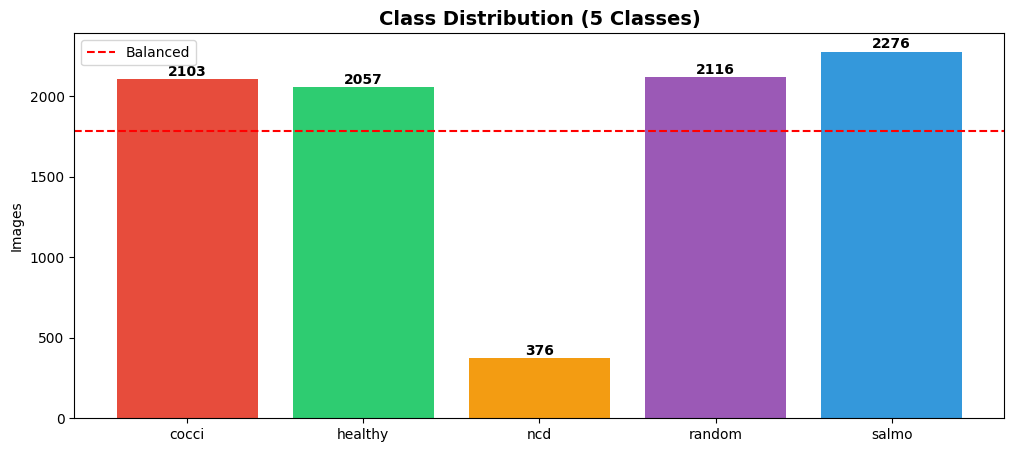


✅ Split summary:
  Train: 6248 images
  Val:   1340 images
  Test:  1340 images

✓ Part 2 Complete


In [2]:
# ============================================================
# PART 2: DATA ANALYSIS & STRATIFIED SPLIT
# ============================================================

import matplotlib.pyplot as plt

def create_stratified_splits(config):
    """Create stratified train/val/test splits and save to file."""
    
    splits_file = f"{config['output_path']}/splits/data_splits.json"
    
    # Check if splits exist
    if os.path.exists(splits_file):
        print("Loading existing splits...")
        with open(splits_file, 'r') as f:
            splits = json.load(f)
        for name in ['train', 'val', 'test']:
            print(f"  {name}: {len(splits[name]['images'])} images")
        return splits
    
    print("Creating new stratified splits...\n")
    
    all_images = []
    all_labels = []
    class_counts = {}
    
    dataset_root = config['dataset_path']
    
    # For each class, search for any directory named exactly like that class
    for class_idx, class_name in enumerate(config['classes']):
        print(f"\n🔎 Searching for class folder(s) named '{class_name}' under {dataset_root}...")
        
        class_images = []
        
        # Walk entire dataset tree once per class
        for root, dirs, files in os.walk(dataset_root):
            # If this directory's name matches the class_name, collect images under it (recursively)
            if os.path.basename(root).lower() == class_name.lower():
                # Collect images under this root (and subfolders)
                for r2, _, files2 in os.walk(root):
                    for f in files2:
                        if f.lower().endswith(('.jpg', '.jpeg', '.png')):
                            class_images.append(os.path.join(r2, f))
        
        class_images = sorted(list(set(class_images)))  # remove duplicates, if any
        class_counts[class_name] = len(class_images)
        
        if len(class_images) == 0:
            print(f"  ⚠️ No images found for class '{class_name}'!")
        else:
            print(f"  ✅ Found {len(class_images)} images for class '{class_name}'")
        
        all_images.extend(class_images)
        all_labels.extend([class_idx] * len(class_images))
    
    # Safety check
    if len(all_images) == 0:
        raise RuntimeError(
            f"No images found under {dataset_root} for any of the classes {config['classes']}.\n"
            "Please run:\n"
            "  !ls -R /kaggle/input/newdataset\n"
            "to inspect the true folder structure and adjust CONFIG['dataset_path'] or class names."
        )
    
    # Calculate imbalance
    total = sum(class_counts.values())
    max_count = max(class_counts.values())
    min_count = min(class_counts.values())
    min_class = min(class_counts, key=class_counts.get)
    
    print(f"\n📊 Total: {total} images")
    print(f"⚠️ Imbalance ratio: {max_count/min_count:.1f}:1")
    print(f"⚠️ Smallest class: {min_class} ({min_count} images)")
    
    # Stratified split
    X_temp, X_test, y_temp, y_test = train_test_split(
        all_images, all_labels,
        test_size=config['test_split'],
        stratify=all_labels,
        random_state=config['seed']
    )
    
    val_ratio = config['val_split'] / (config['train_split'] + config['val_split'])
    X_train, X_val, y_train, y_val = train_test_split(
        X_temp, y_temp,
        test_size=val_ratio,
        stratify=y_temp,
        random_state=config['seed']
    )
    
    splits = {
        'train': {'images': X_train, 'labels': y_train},
        'val':   {'images': X_val,   'labels': y_val},
        'test':  {'images': X_test,  'labels': y_test},
        'class_counts': class_counts
    }
    
    # Save
    os.makedirs(f"{config['output_path']}/splits", exist_ok=True)
    with open(splits_file, 'w') as f:
        json.dump(splits, f)
    
    # Visualize
    fig, ax = plt.subplots(figsize=(12, 5))
    colors = ['#e74c3c', '#2ecc71', '#f39c12', '#9b59b6', '#3498db']
    colors = colors[:len(config['classes'])]  # in case classes != 5
    
    counts_list = [class_counts.get(c, 0) for c in config['classes']]
    bars = ax.bar(config['classes'], counts_list, color=colors)
    ax.axhline(y=total/len(config['classes']), color='red', linestyle='--', label='Balanced')
    ax.set_title(f'Class Distribution ({len(config["classes"])} Classes)', fontsize=14, fontweight='bold')
    ax.set_ylabel('Images')
    for bar, c in zip(bars, config['classes']):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 20,
                f'{class_counts.get(c, 0)}', ha='center', fontweight='bold')
    ax.legend()
    plt.savefig(f"{config['output_path']}/class_distribution.png", dpi=150, bbox_inches='tight')
    plt.show()
    
    print(f"\n✅ Split summary:")
    print(f"  Train: {len(X_train)} images")
    print(f"  Val:   {len(X_val)} images")
    print(f"  Test:  {len(X_test)} images")
    
    return splits

# Create splits
data_splits = create_stratified_splits(CONFIG)
print(f"\n✓ Part 2 Complete")


In [3]:
# ============================================================
# PART 3: DATA PIPELINE
# ============================================================

def load_image(image_path, label, img_size):
    """Load and resize image - keep 0-255 range for EfficientNet"""
    image = tf.io.read_file(image_path)
    image = tf.image.decode_jpeg(image, channels=3)
    image = tf.image.resize(image, [img_size, img_size])
    image = tf.cast(image, tf.float32)  # Keep 0-255 range
    return image, label

def create_dataset(image_paths, labels, config, is_training=False):
    """Create tf.data.Dataset"""
    
    dataset = tf.data.Dataset.from_tensor_slices((list(image_paths), list(labels)))
    
    if is_training:
        dataset = dataset.shuffle(buffer_size=len(image_paths), seed=config['seed'])
    
    dataset = dataset.map(
        lambda x, y: load_image(x, y, config['img_size']),
        num_parallel_calls=tf.data.AUTOTUNE
    )
    
    dataset = dataset.batch(config['batch_size'])
    dataset = dataset.prefetch(tf.data.AUTOTUNE)
    
    return dataset

# Create datasets
print("Creating datasets...")
train_ds = create_dataset(data_splits['train']['images'], data_splits['train']['labels'], CONFIG, is_training=True)
val_ds = create_dataset(data_splits['val']['images'], data_splits['val']['labels'], CONFIG, is_training=False)
test_ds = create_dataset(data_splits['test']['images'], data_splits['test']['labels'], CONFIG, is_training=False)

# Verify
for images, labels in train_ds.take(1):
    print(f"\n✅ Batch shape: {images.shape}")
    print(f"✅ Image range: [{images.numpy().min():.0f}, {images.numpy().max():.0f}]")
    print(f"✅ Labels sample: {labels.numpy()[:5]}")

# Calculate class weights
print("\nCalculating class weights...")
all_train_labels = []
for _, labels in train_ds:
    all_train_labels.extend(labels.numpy())

class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(all_train_labels),
    y=all_train_labels
)
class_weight_dict = dict(enumerate(class_weights))

print("\nClass weights (higher = more attention):")
for idx, weight in class_weight_dict.items():
    print(f"  {CONFIG['classes'][idx]}: {weight:.3f}")

print(f"\n✓ Part 3 Complete")


Creating datasets...


I0000 00:00:1764978897.141939      47 gpu_device.cc:2022] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13942 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1764978897.142653      47 gpu_device.cc:2022] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13942 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5



✅ Batch shape: (16, 300, 300, 3)
✅ Image range: [0, 255]
✅ Labels sample: [3 4 3 4 4]

Calculating class weights...

Class weights (higher = more attention):
  cocci: 0.849
  healthy: 0.868
  ncd: 4.733
  random: 0.844
  salmo: 0.784

✓ Part 3 Complete


In [4]:
# ============================================================
# PART 4: MODEL ARCHITECTURE - EfficientNetB3
# ============================================================

from tensorflow.keras import layers, Model
from tensorflow.keras.applications import EfficientNetB3

def create_model(num_classes, img_size):
    """
    Create EfficientNetB3 model with embedded preprocessing.
    
    IMPORTANT: EfficientNet preprocessing is built into the model,
    so we just pass raw images (0-255). Adding a Rescaling layer
    ensures this works the same in TFLite.
    """
    
    inputs = layers.Input(shape=(img_size, img_size, 3), name='input_image')
    
    # Data augmentation (only active during training)
    x = layers.RandomFlip("horizontal")(inputs)
    x = layers.RandomRotation(0.15)(x)
    x = layers.RandomZoom(0.1)(x)
    x = layers.RandomBrightness(0.1)(x)
    x = layers.RandomContrast(0.1)(x)
    
    # EfficientNetB3 base model
    # Note: EfficientNet has built-in preprocessing (Rescaling + Normalization)
    base_model = EfficientNetB3(
        include_top=False,
        weights='imagenet',
        input_tensor=x,
        pooling=None
    )
    
    # Freeze early layers (first 70%)
    base_model.trainable = True
    freeze_until = int(len(base_model.layers) * 0.7)
    for layer in base_model.layers[:freeze_until]:
        layer.trainable = False
    
    trainable = len([l for l in base_model.layers if l.trainable])
    print(f"  Base model layers: {len(base_model.layers)}")
    print(f"  Frozen layers: {freeze_until}")
    print(f"  Trainable layers: {trainable}")
    
    # Custom classification head
    x = layers.GlobalAveragePooling2D(name='pool')(base_model.output)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.3)(x)
    x = layers.Dense(512, activation='relu')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.2)(x)
    x = layers.Dense(256, activation='relu')(x)
    x = layers.Dropout(0.2)(x)
    
    outputs = layers.Dense(num_classes, activation='softmax', name='predictions')(x)
    
    model = Model(inputs, outputs, name='chicken_disease_efficientnetb3')
    
    return model, base_model

# Create model
print("="*60)
print("CREATING EfficientNetB3 MODEL")
print("="*60)

model, base_model = create_model(len(CONFIG['classes']), CONFIG['img_size'])

# Compile
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=CONFIG['initial_lr']),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Summary
model.summary()

total_params = model.count_params()
print(f"\n✅ Model: EfficientNetB3")
print(f"✅ Input: {CONFIG['img_size']}x{CONFIG['img_size']}x3")
print(f"✅ Output: {len(CONFIG['classes'])} classes")
print(f"✅ Total parameters: {total_params:,}")

print(f"\n✓ Part 4 Complete")


CREATING EfficientNetB3 MODEL
43941136/43941136 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
  Base model layers: 390
  Frozen layers: 273
  Trainable layers: 117


Model: "chicken_disease_efficientnetb3"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_image         │ (None, 300, 300,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ random_flip         │ (None, 300, 300,  │          0 │ input_image[0][0] │
│ (RandomFlip)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ random_rotation     │ (None, 300, 300,  │          0 │ random_flip[0][0] │
│ (RandomRotation)    │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ random_zoom         │ (None, 300, 300,  │          0 │ random_rotation[… │
│ (RandomZoom)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ random_brightness   │ (None, 300, 300,  │          0 │ random_zoom[0][0] │
│ (RandomBrightness)  │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ random_contrast     │ (None, 300, 300,  │          0 │ random_brightnes… │
│ (RandomContrast)    │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling           │ (None, 300, 300,  │          0 │ random_contrast[… │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ normalization       │ (None, 300, 300,  │          7 │ rescaling[0][0]   │
│ (Normalization)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling_1         │ (None, 300, 300,  │          0 │ normalization[0]… │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv_pad       │ (None, 301, 301,  │          0 │ rescaling_1[0][0] │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv (Conv2D)  │ (None, 150, 150,  │      1,080 │ stem_conv_pad[0]… │
│                     │ 40)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_bn             │ (None, 150, 150,  │        160 │ stem_conv[0][0]   │
│ (BatchNormalizatio… │ 40)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_activation     │ (None, 150, 150,  │          0 │ stem_bn[0][0]     │
│ (Activation)        │ 40)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_dwconv      │ (None, 150, 150,  │        360 │ stem_activation[… │
│ (DepthwiseConv2D)   │ 40)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_bn          │ (None, 150, 150,  │        160 │ block1a_dwconv[0… │
│ (BatchNormalizatio… │ 40)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_activation  │ (None, 150, 150,  │          0 │ block1a_bn[0][0]  │
│ (Activation)        │ 40)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_squeeze  │ (None, 40)        │          0 │ block1a_activati

 Total params: 11,711,284 (44.68 MB)

 Trainable params: 9,317,123 (35.54 MB)

 Non-trainable params: 2,394,161 (9.13 MB)


✅ Model: EfficientNetB3
✅ Input: 300x300x3
✅ Output: 5 classes
✅ Total parameters: 11,711,284

✓ Part 4 Complete


In [ ]:
# ============================================================
# PART 5: TRAINING (CLEAN, NO RESUME, NO PICKLE ERRORS)
# ============================================================

from tensorflow.keras.callbacks import (
    ModelCheckpoint, EarlyStopping, ReduceLROnPlateau, CSVLogger
)

# ------------------------------------------------------------
# PATHS
# ------------------------------------------------------------
BEST_MODEL_PATH = f"{CONFIG['output_path']}/best_model.keras"          # full model
CHECKPOINT_PATH = f"{CONFIG['output_path']}/checkpoints/epoch_{{epoch:03d}}.weights.h5"
LOG_PATH = f"{CONFIG['output_path']}/logs/training.csv"
FINAL_MODEL_PATH = f"{CONFIG['output_path']}/final_model.keras"

# Clear logs if exist
if os.path.exists(LOG_PATH):
    os.remove(LOG_PATH)

# ------------------------------------------------------------
# CALLBACKS (clean, safe)
# ------------------------------------------------------------
callbacks = [
    # Save weights each epoch
    ModelCheckpoint(CHECKPOINT_PATH, save_weights_only=True, verbose=0),

    # Save best full model
    ModelCheckpoint(BEST_MODEL_PATH, monitor='val_accuracy',
                    save_best_only=True, mode='max', verbose=1),

    EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True, verbose=1),

    ReduceLROnPlateau(monitor='val_loss', factor=0.5,
                      patience=4, min_lr=1e-7, verbose=1),

    CSVLogger(LOG_PATH, append=True)
]

# ------------------------------------------------------------
# PHASE 1: TRAIN WITH 70% FROZEN LAYERS
# ------------------------------------------------------------
print("\n" + "="*60)
print("PHASE 1: TRAINING (70% base frozen)")
print("="*60)

phase1_epochs = 30

history1 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=phase1_epochs,
    class_weight=class_weight_dict,
    callbacks=callbacks,
    verbose=1
)

best_val_acc = max(history1.history["val_accuracy"])
print(f"\n⭐ Best Phase 1 Val Accuracy: {best_val_acc:.2%}")

# ------------------------------------------------------------
# PHASE 2: FINE-TUNING (50% FROZEN)
# ------------------------------------------------------------
if best_val_acc > 0.60:
    print("\n" + "="*60)
    print("PHASE 2: FINE-TUNING (Unfreeze more layers)")
    print("="*60)

    freeze_until = int(len(base_model.layers) * 0.5)

    for layer in base_model.layers[freeze_until:]:
        layer.trainable = True

    print(f"Unfroze last {len(base_model.layers) - freeze_until} layers.")

    # Recompile with lower LR
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=CONFIG["initial_lr"] / 10),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    history2 = model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=phase1_epochs + 30,
        initial_epoch=phase1_epochs,
        class_weight=class_weight_dict,
        callbacks=callbacks,
        verbose=1
    )

    best_val_acc = max(best_val_acc, max(history2.history["val_accuracy"]))

# ------------------------------------------------------------
# SAVE FINAL MODEL
# ------------------------------------------------------------
model.save(FINAL_MODEL_PATH)

print("\n" + "="*60)
print("TRAINING COMPLETE")
print("="*60)
print(f"🔥 FINAL BEST VALIDATION ACCURACY: {best_val_acc:.2%}")
print(f"📦 Saved best model: {BEST_MODEL_PATH}")
print(f"📦 Saved final model: {FINAL_MODEL_PATH}")
print(f"\n✓ Part 5 Complete")



PHASE 1: TRAINING (70% base frozen)
Epoch 1/30


E0000 00:00:1764979001.438678      47 meta_optimizer.cc:966] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/chicken_disease_efficientnetb3_1/block1b_drop_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer
I0000 00:00:1764979006.826664     106 cuda_dnn.cc:529] Loaded cuDNN version 90300


391/391 ━━━━━━━━━━━━━━━━━━━━ 0s 206ms/step - accuracy: 0.8368 - loss: 0.5516
Epoch 1: val_accuracy improved from -inf to 0.97388, saving model to /kaggle/working/best_model.keras
391/391 ━━━━━━━━━━━━━━━━━━━━ 141s 271ms/step - accuracy: 0.8369 - loss: 0.5512 - val_accuracy: 0.9739 - val_loss: 0.0752 - learning_rate: 5.0000e-04
Epoch 2/30
391/391 ━━━━━━━━━━━━━━━━━━━━ 0s 213ms/step - accuracy: 0.9393 - loss: 0.2172
Epoch 2: val_accuracy improved from 0.97388 to 0.97761, saving model to /kaggle/working/best_model.keras
391/391 ━━━━━━━━━━━━━━━━━━━━ 98s 250ms/step - accuracy: 0.9393 - loss: 0.2172 - val_accuracy: 0.9776 - val_loss: 0.0697 - learning_rate: 5.0000e-04
Epoch 3/30
391/391 ━━━━━━━━━━━━━━━━━━━━ 0s 211ms/step - accuracy: 0.9564 - loss: 0.1486
Epoch 3: val_accuracy improved from 0.97761 to 0.98209, saving model to /kaggle/working/best_model.keras
391/391 ━━━━━━━━━━━━━━━━━━━━ 97s 248ms/step - accuracy: 0.9564 - loss: 0.1486 - val_accuracy: 0.9821 - val_loss: 0.0579 - learning_rate: 5

In [ ]:
# ============================================================
# PART 6: EVALUATION ON TEST SET
# ============================================================

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, auc
from sklearn.preprocessing import label_binarize

print("="*60)
print("EVALUATION ON HELD-OUT TEST SET")
print("="*60)

# Load best model
model.load_weights(BEST_MODEL_PATH)

# Evaluate
test_loss, test_acc = model.evaluate(test_ds)
print(f"\n📊 Test Loss: {test_loss:.4f}")
print(f"📊 Test Accuracy: {test_acc:.4f}")

# Get predictions
y_true, y_pred, y_proba = [], [], []
for images, labels in test_ds:
    preds = model.predict(images, verbose=0)
    y_proba.extend(preds)
    y_pred.extend(np.argmax(preds, axis=1))
    y_true.extend(labels.numpy())

y_true = np.array(y_true)
y_pred = np.array(y_pred)
y_proba = np.array(y_proba)

# Classification report
print("\n" + "="*60)
print("CLASSIFICATION REPORT")
print("="*60)
print(classification_report(y_true, y_pred, target_names=CONFIG['classes']))

# Save report
report = classification_report(y_true, y_pred, target_names=CONFIG['classes'], output_dict=True)
pd.DataFrame(report).T.to_csv(f"{CONFIG['output_path']}/classification_report.csv")

# ============================================================
# VISUALIZATIONS
# ============================================================
fig, axes = plt.subplots(2, 2, figsize=(14, 12))

# 1. Loss curve
ax1 = axes[0, 0]
log_df = pd.read_csv(LOG_PATH)
ax1.plot(log_df['loss'], label='Train Loss', linewidth=2)
ax1.plot(log_df['val_loss'], label='Val Loss', linewidth=2)
ax1.axvline(x=35, color='gray', linestyle='--', alpha=0.5, label='Fine-tune start')
ax1.set_title('Loss Curve', fontsize=14, fontweight='bold')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Loss')
ax1.legend()
ax1.grid(True, alpha=0.3)

# 2. Accuracy curve
ax2 = axes[0, 1]
ax2.plot(log_df['accuracy'], label='Train Acc', linewidth=2)
ax2.plot(log_df['val_accuracy'], label='Val Acc', linewidth=2)
ax2.axhline(y=test_acc, color='green', linestyle='--', linewidth=2, label=f'Test: {test_acc:.1%}')
ax2.axvline(x=35, color='gray', linestyle='--', alpha=0.5)
ax2.set_title('Accuracy Curve', fontsize=14, fontweight='bold')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Accuracy')
ax2.legend()
ax2.grid(True, alpha=0.3)

# 3. Confusion matrix
ax3 = axes[1, 0]
cm = confusion_matrix(y_true, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=CONFIG['classes'], yticklabels=CONFIG['classes'], ax=ax3)
ax3.set_title('Confusion Matrix', fontsize=14, fontweight='bold')
ax3.set_xlabel('Predicted')
ax3.set_ylabel('True')

# 4. Per-class accuracy
ax4 = axes[1, 1]
class_acc = cm.diagonal() / cm.sum(axis=1)
colors = ['#e74c3c', '#2ecc71', '#f39c12', '#9b59b6', '#3498db']
bars = ax4.bar(CONFIG['classes'], class_acc, color=colors)
ax4.axhline(y=test_acc, color='red', linestyle='--', linewidth=2, label=f'Overall: {test_acc:.1%}')
ax4.set_title('Per-Class Accuracy', fontsize=14, fontweight='bold')
ax4.set_ylabel('Accuracy')
ax4.set_ylim(0, 1.1)
for bar, acc in zip(bars, class_acc):
    ax4.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.02,
             f'{acc:.1%}', ha='center', fontweight='bold')
ax4.legend()

plt.tight_layout()
plt.savefig(f"{CONFIG['output_path']}/evaluation_results.png", dpi=300, bbox_inches='tight')
plt.show()

# ============================================================
# ROC CURVES
# ============================================================
fig, ax = plt.subplots(figsize=(10, 8))
y_true_bin = label_binarize(y_true, classes=range(len(CONFIG['classes'])))
colors = ['#e74c3c', '#2ecc71', '#f39c12', '#9b59b6', '#3498db']

for i, (class_name, color) in enumerate(zip(CONFIG['classes'], colors)):
    fpr, tpr, _ = roc_curve(y_true_bin[:, i], y_proba[:, i])
    roc_auc = auc(fpr, tpr)
    ax.plot(fpr, tpr, color=color, linewidth=2, label=f'{class_name} (AUC={roc_auc:.3f})')

ax.plot([0, 1], [0, 1], 'k--', linewidth=1)
ax.set_xlabel('False Positive Rate')
ax.set_ylabel('True Positive Rate')
ax.set_title('ROC Curves', fontsize=14, fontweight='bold')
ax.legend(loc='lower right')
ax.grid(True, alpha=0.3)
plt.savefig(f"{CONFIG['output_path']}/roc_curves.png", dpi=300, bbox_inches='tight')
plt.show()

# Save metrics
metrics = {
    'test_loss': float(test_loss),
    'test_accuracy': float(test_acc),
    'per_class_accuracy': {c: float(a) for c, a in zip(CONFIG['classes'], class_acc)}
}
with open(f"{CONFIG['output_path']}/metrics.json", 'w') as f:
    json.dump(metrics, f, indent=2)

print(f"\n✓ Part 6 Complete")


In [ ]:
# ============================================================
# PART 7: TFLITE CONVERSION
# ============================================================

from tensorflow.keras.applications import EfficientNetB3

print("="*60)
print("CREATING INFERENCE MODEL & TFLITE")
print("="*60)

def create_inference_model(num_classes, img_size):
    """Inference model WITHOUT augmentation layers"""
    
    inputs = layers.Input(shape=(img_size, img_size, 3), name='input_image')
    
    # NO augmentation - direct to base model
    base = EfficientNetB3(
        include_top=False,
        weights='imagenet',
        input_tensor=inputs
    )
    
    x = layers.GlobalAveragePooling2D(name='pool')(base.output)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.3)(x)
    x = layers.Dense(512, activation='relu')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.2)(x)
    x = layers.Dense(256, activation='relu')(x)
    x = layers.Dropout(0.2)(x)
    outputs = layers.Dense(num_classes, activation='softmax', name='predictions')(x)
    
    return Model(inputs, outputs, name='inference_model')

# Create inference model
print("Creating inference model...")
inference_model = create_inference_model(len(CONFIG['classes']), CONFIG['img_size'])

# Copy weights
print("Copying weights from trained model...")
trained_model = tf.keras.models.load_model(BEST_MODEL_PATH)

weights_copied = 0
for layer in inference_model.layers:
    try:
        trained_layer = trained_model.get_layer(layer.name)
        weights = trained_layer.get_weights()
        if weights:
            layer.set_weights(weights)
            weights_copied += 1
    except:
        pass
print(f"  Copied {weights_copied} layers")

# Verify
print("\nVerifying inference model...")
inference_model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
inf_loss, inf_acc = inference_model.evaluate(test_ds, verbose=0)
print(f"  Inference model accuracy: {inf_acc:.2%}")

if abs(inf_acc - test_acc) > 0.03:
    print("  ⚠️ Accuracy differs - checking weight copy...")
else:
    print("  ✅ Accuracy matches!")

# Save H5
inference_model.save(f"{CONFIG['output_path']}/inference_model.h5")
print(f"\n✅ Saved: inference_model.h5")

# ============================================================
# CONVERT TO TFLITE
# ============================================================
print("\nConverting to TFLite...")

# Float32 TFLite
converter = tf.lite.TFLiteConverter.from_keras_model(inference_model)
tflite_model = converter.convert()

tflite_path = f"{CONFIG['output_path']}/model.tflite"
with open(tflite_path, 'wb') as f:
    f.write(tflite_model)
print(f"✅ model.tflite ({os.path.getsize(tflite_path)/1024/1024:.1f} MB)")

# Float16 quantized
converter_fp16 = tf.lite.TFLiteConverter.from_keras_model(inference_model)
converter_fp16.optimizations = [tf.lite.Optimize.DEFAULT]
converter_fp16.target_spec.supported_types = [tf.float16]
tflite_fp16 = converter_fp16.convert()

tflite_fp16_path = f"{CONFIG['output_path']}/model_fp16.tflite"
with open(tflite_fp16_path, 'wb') as f:
    f.write(tflite_fp16)
print(f"✅ model_fp16.tflite ({os.path.getsize(tflite_fp16_path)/1024/1024:.1f} MB)")

# Labels
with open(f"{CONFIG['output_path']}/labels.txt", 'w') as f:
    for label in CONFIG['classes']:
        f.write(f"{label}\n")
print(f"✅ labels.txt")

# ============================================================
# VERIFY TFLITE
# ============================================================
print("\nVerifying TFLite model...")
interpreter = tf.lite.Interpreter(model_path=tflite_path)
interpreter.allocate_tensors()
input_details = interpreter.get_input_details()
output_details = interpreter.get_output_details()

print(f"  Input: {input_details[0]['shape']} {input_details[0]['dtype']}")
print(f"  Output: {output_details[0]['shape']}")

# Quick accuracy check
correct = 0
total = 0
for images, labels in test_ds.take(5):
    for i in range(len(images)):
        img = np.expand_dims(images[i].numpy(), 0)
        interpreter.set_tensor(input_details[0]['index'], img)
        interpreter.invoke()
        pred = np.argmax(interpreter.get_tensor(output_details[0]['index'])[0])
        if pred == labels[i].numpy():
            correct += 1
        total += 1

print(f"  TFLite accuracy (sample): {correct/total:.1%}")

print(f"\n✓ Part 7 Complete")
